# 0_1 What is in the Human Spatial Atlas

Assembled by agents from 17 public sources. This notebook asks what it contains, who it
represents, and where it is blind - before anything is built on it.

## Setup

In [1]:
import os
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from pathlib import Path

HSA = Path(os.environ.get("HSA_ROOT", "/data/yzy21/yy/space_agent/hsa"))  # override with HSA_ROOT to run elsewhere
FIG = HSA / "explore"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
mpl.rcParams.update({"figure.dpi": 130, "savefig.dpi": 160, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.titlelocation": "left", "axes.titlesize": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white"})

## Load the catalogue

In [2]:
man = pd.read_csv(HSA / "runs/sample_manifest.csv", low_memory=False)
led = pd.read_csv(HSA / "runs/materialise_ledger.csv")
ok = led[led.status.astype(str).str.startswith("ok") | led.status.astype(str).eq("already_done")]
a = man.merge(ok[["source", "accession", "sample_id", "path", "bytes_out"]],
              on=["source", "accession", "sample_id"]).query("usable")
print(f"{len(a):,} materialised samples | {a.accession.nunique():,} studies | {a.source.nunique()} sources")
print(f"{a.n_cells.sum()/1e6:,.0f} million spots/cells | {a.bytes_out.sum()/1e9:.0f} GB")

7,719 materialised samples | 1,483 studies | 19 sources
903 million spots/cells | 389 GB


## 1. Composition

A Visium "sample" is ~3,500 spots, each pooling tens of cells; a Xenium sample is ~100,000
segmented cells. Counting samples and counting measurements give different pictures.

In [3]:
CELL_TECH = {"Xenium", "CosMx", "MERFISH", "seqFISH", "STARmap",
             "cell-level WTA", "cell-level (unknown platform)"}
comp = (a.groupby("technology_resolved")
          .agg(samples=("sample_id", "size"), units=("n_cells", "sum"),
               studies=("accession", "nunique"), median_units=("n_cells", "median")))
comp["kind"] = ["cell" if t in CELL_TECH else "spot/bin" for t in comp.index]
comp = comp[comp.samples >= 5].sort_values("samples", ascending=False)
display(comp.assign(units_M=(comp.units / 1e6).round(1)).drop(columns="units"))

,samples,studies,median_units,kind,units_M
technology_resolved,,,,,
Visium,5440,919,3477.5,spot/bin,25.6
Xenium,1294,225,67280.5,cell,194.5
cell-level WTA,277,72,167254.0,cell,515.6
CosMx,209,41,2202.0,cell,20.5
Slide-seq,199,185,22188.0,spot/bin,4.5
MERFISH,149,18,391560.0,cell,64.8
Stereo-seq,106,8,68328.5,spot/bin,16.9
cell-level (unknown platform),27,11,4932.0,cell,5.7
Other,6,3,57800.0,spot/bin,3.0


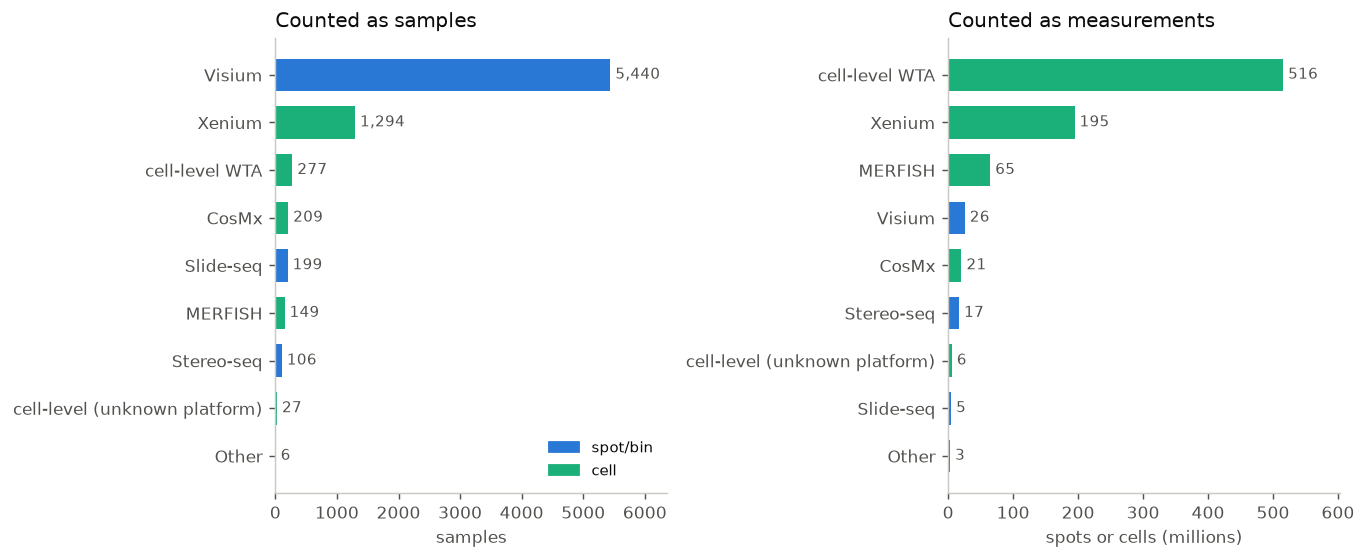

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.4))
for ax, col, lab, sc in [(axes[0], "samples", "samples", 1),
                         (axes[1], "units", "spots or cells (millions)", 1e6)]:
    d = comp.sort_values(col)
    ax.barh(range(len(d)), d[col] / sc,
            color=[C[0] if k == "spot/bin" else C[2] for k in d.kind], height=.68)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index); ax.set_xlabel(lab)
    for i, v in enumerate(d[col] / sc):
        ax.text(v + d[col].max() / sc * .015, i, f"{v:,.0f}", va="center",
                fontsize=8.2, color=INK2)
    ax.set_xlim(0, d[col].max() / sc * 1.17)
axes[0].set_title("Counted as samples", color=INK)
axes[1].set_title("Counted as measurements", color=INK)
h = [mpl.patches.Patch(color=C[0], label="spot/bin"), mpl.patches.Patch(color=C[2], label="cell")]
axes[0].legend(handles=h, frameon=False, loc="lower right", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "f01_composition.png", bbox_inches="tight"); plt.show()

## 2. Metadata completeness

Technology is known for every sample because it is inferable from the files. Everything about
the donor depends on what the depositor wrote.

In [5]:
fields = ["technology_resolved", "tissue", "species", "disease_state", "disease_level1",
          "condition", "preservation", "publication", "donor_id", "sex",
          "development_stage", "age_group", "self_reported_ethnicity"]
unk = lambda s: s.isna() | s.astype(str).str.strip().eq("") | s.astype(str).str.lower().isin(
    ["unknown", "nan", "none", "na", "not reported"])
cov = pd.DataFrame({"field": [f.replace("_", " ") for f in fields],
                    "pct": [(~unk(a[f])).mean() * 100 for f in fields],
                    "distinct": [a[f].nunique() for f in fields]}).sort_values("pct")
display(cov.set_index("field").round(1))

,pct,distinct
field,,
self reported ethnicity,2.3,18
age group,23.3,9
development stage,23.8,155
sex,29.7,4
preservation,38.7,4
donor id,49.8,1661
publication,58.9,435
condition,78.5,2719
disease level1,80.5,21


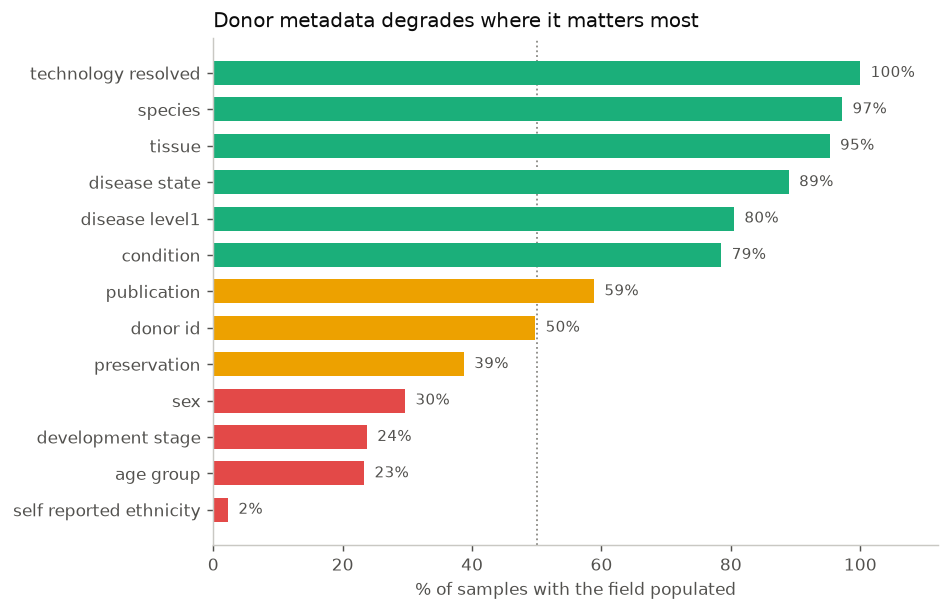

In [6]:
fig, ax = plt.subplots(figsize=(7.4, 4.8))
cols = [C[7] if p < 35 else (C[3] if p < 75 else C[2]) for p in cov.pct]
ax.barh(range(len(cov)), cov.pct, color=cols, height=.66)
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.field)
ax.set_xlabel("% of samples with the field populated"); ax.set_xlim(0, 112)
for i, p in enumerate(cov.pct):
    ax.text(p + 1.6, i, f"{p:.0f}%", va="center", fontsize=8.4, color=INK2)
ax.axvline(50, color=MUTED, lw=1, ls=":", zorder=0)
ax.set_title("Donor metadata degrades where it matters most", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f02_metadata.png", bbox_inches="tight"); plt.show()

## 3. Tissue coverage

In [7]:
t = a[~unk(a.tissue)]
tc = t.tissue.value_counts()
cum = tc.cumsum() / tc.sum() * 100
half = int(np.searchsorted(cum.values, 50) + 1)
eighty = int(np.searchsorted(cum.values, 80) + 1)
print(f"{t.tissue.nunique()} tissues | half the atlas is {half} tissues | 80% is {eighty}")
display(tc.head(12).to_frame("samples"))

295 tissues | half the atlas is 11 tissues | 80% is 51


,samples
tissue,
brain,804
lung,732
pancreas,414
skin_of_body,345
breast,334
kidney,277
liver,245
colon,169
brodmann_1909_area_44,137


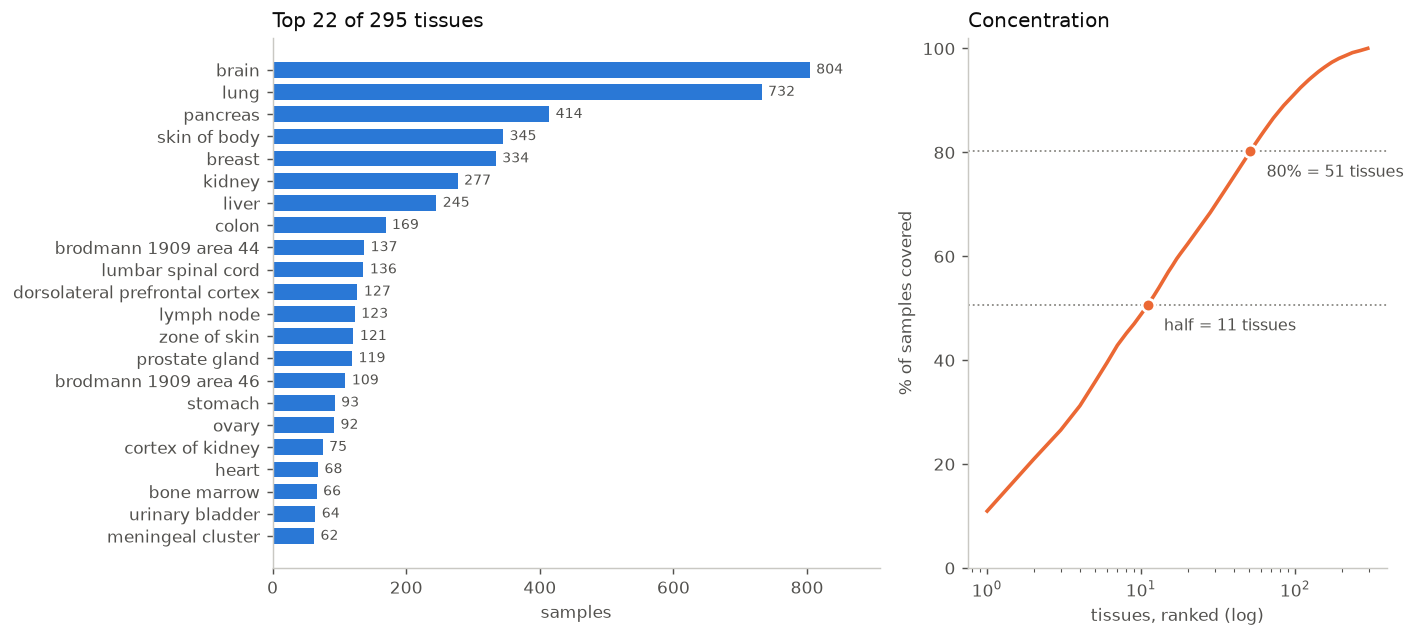

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.0), gridspec_kw={"width_ratios": [1.45, 1]})
top = tc.head(22).sort_values()
axes[0].barh(range(len(top)), top.values, color=C[0], height=.7)
axes[0].set_yticks(range(len(top)))
axes[0].set_yticklabels([x.replace("_", " ")[:30] for x in top.index])
axes[0].set_xlabel("samples"); axes[0].set_xlim(0, top.max() * 1.13)
for i, v in enumerate(top.values):
    axes[0].text(v + top.max() * .012, i, f"{v:,}", va="center", fontsize=8, color=INK2)
axes[0].set_title(f"Top 22 of {t.tissue.nunique()} tissues", color=INK)
axes[1].plot(np.arange(1, len(cum) + 1), cum.values, color=C[1], lw=2)
axes[1].set_xscale("log"); axes[1].set_xlabel("tissues, ranked (log)")
axes[1].set_ylabel("% of samples covered"); axes[1].set_ylim(0, 102)
for k, lab in [(half, "half"), (eighty, "80%")]:
    axes[1].axhline(cum.values[k - 1], color=MUTED, lw=1, ls=":", zorder=0)
    axes[1].plot([k], [cum.values[k - 1]], "o", ms=7, color=C[1], mec="white", mew=1.5)
    axes[1].annotate(f"{lab} = {k} tissues", (k, cum.values[k - 1]),
                     textcoords="offset points", xytext=(9, -14), fontsize=8.6, color=INK2)
axes[1].set_title("Concentration", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f03_tissue.png", bbox_inches="tight"); plt.show()

## 4. Study concentration

Samples within a study share donors, protocol and batch, so the effective n for any statistical
use is closer to the number of studies.

In [9]:
s = a.accession.value_counts()
cums = s.cumsum() / s.sum() * 100
print(f"{len(s):,} studies | median {s.median():.0f} samples | "
      f"{int((s == 1).sum()):,} contribute exactly one")
for q in (5, 10, 25):
    print(f"  top {q:2d}% of studies = {cums.values[int(len(s)*q/100)-1]:.0f}% of samples")

1,483 studies | median 1 samples | 843 contribute exactly one
  top  5% of studies = 44% of samples
  top 10% of studies = 59% of samples
  top 25% of studies = 79% of samples


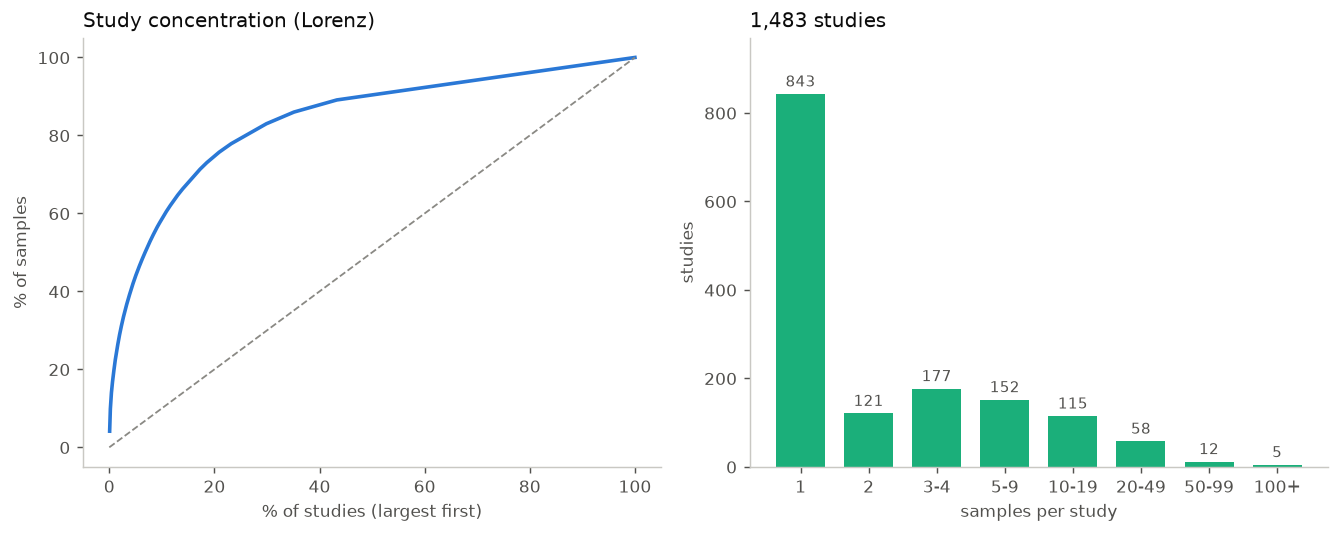

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
axes[0].plot(np.arange(1, len(s) + 1) / len(s) * 100, cums.values, color=C[0], lw=2)
axes[0].plot([0, 100], [0, 100], color=MUTED, lw=1, ls="--")
axes[0].set_xlabel("% of studies (largest first)"); axes[0].set_ylabel("% of samples")
axes[0].set_title("Study concentration (Lorenz)", color=INK)
bins = [1, 2, 3, 5, 10, 20, 50, 100, 10000]
labs = ["1", "2", "3-4", "5-9", "10-19", "20-49", "50-99", "100+"]
h = pd.cut(s, bins=bins, right=False, labels=labs).value_counts().reindex(labs)
axes[1].bar(range(len(h)), h.values, color=C[2], width=.72)
axes[1].set_xticks(range(len(h))); axes[1].set_xticklabels(labs)
axes[1].set_xlabel("samples per study"); axes[1].set_ylabel("studies")
for i, v in enumerate(h.values):
    axes[1].text(i, v + h.max() * .02, f"{v}", ha="center", fontsize=8.2, color=INK2)
axes[1].set_ylim(0, h.max() * 1.15)
axes[1].set_title(f"{len(s):,} studies", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f04_studies.png", bbox_inches="tight"); plt.show()

## 5. Depth per unit

In [11]:
q = a[a.median_counts.notna() & a.median_counts.gt(0)]
order = [t for t in q.groupby("technology_resolved").median_counts.median().sort_values().index
         if (q.technology_resolved == t).sum() >= 15]
display(q[q.technology_resolved.isin(order)].groupby("technology_resolved")
        .median_counts.describe()[["count", "25%", "50%", "75%"]].round(0).loc[order])

,count,25%,50%,75%
technology_resolved,,,,
MERFISH,144.0,33.0,54.0,81.0
Xenium,1290.0,52.0,115.0,204.0
Slide-seq,178.0,71.0,142.0,264.0
cell-level WTA,270.0,25.0,207.0,1591.0
CosMx,209.0,660.0,898.0,1329.0
Stereo-seq,106.0,976.0,1761.0,2935.0
Visium,5339.0,1714.0,3972.0,9409.0
cell-level (unknown platform),27.0,490.0,5901.0,42362.0


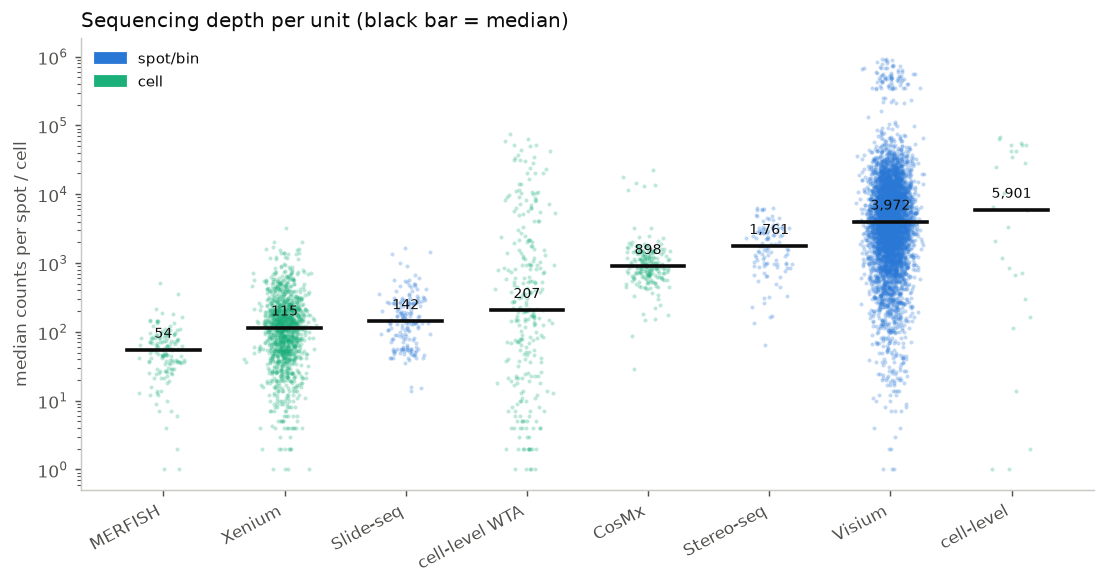

In [12]:
fig, ax = plt.subplots(figsize=(8.6, 4.6))
rng = np.random.default_rng(0)
for i, t in enumerate(order):
    v = q.loc[q.technology_resolved.eq(t), "median_counts"].values
    ax.scatter(rng.normal(i, .085, len(v)), v, s=5,
               color=C[2] if t in CELL_TECH else C[0], alpha=.28, lw=0)
    ax.plot([i - .3, i + .3], [np.median(v)] * 2, color=INK, lw=2, zorder=5)
    ax.text(i, np.median(v) * 1.5, f"{np.median(v):,.0f}", ha="center", fontsize=8, zorder=6)
ax.set_yscale("log"); ax.set_xticks(range(len(order)))
ax.set_xticklabels([t.replace(" (unknown platform)", "") for t in order], rotation=28, ha="right")
ax.set_ylabel("median counts per spot / cell")
ax.legend(handles=[mpl.patches.Patch(color=C[0], label="spot/bin"),
                   mpl.patches.Patch(color=C[2], label="cell")],
          frameon=False, loc="upper left", fontsize=8.5)
ax.set_title("Sequencing depth per unit (black bar = median)", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f05_depth.png", bbox_inches="tight"); plt.show()

## 6. What the atlas can actually power

The usable unit for a comparison is tissue x condition.

In [13]:
d = a[~unk(a.tissue) & ~unk(a.disease_state)]
piv = (d[d.tissue.isin(d.tissue.value_counts().head(18).index)]
       .pivot_table(index="tissue", columns="disease_state", values="sample_id",
                    aggfunc="count", fill_value=0))
keep = [c_ for c_ in ["healthy", "disease"] if c_ in piv.columns]
piv = piv[keep].loc[piv[keep].sum(axis=1).sort_values().index]
paired = piv[(piv.get("healthy", 0) >= 10) & (piv.get("disease", 0) >= 10)]
print(f"tissues with >=10 samples on BOTH sides: {len(paired)} of {d.tissue.nunique()}")
display(piv.sort_values("disease", ascending=False))

tissues with >=10 samples on BOTH sides: 14 of 281


disease_state,healthy,disease
tissue,,
brain,10,732
lung,161,518
pancreas,66,345
breast,23,304
liver,45,193
kidney,45,180
skin_of_body,100,168
prostate_gland,1,118
zone_of_skin,7,110


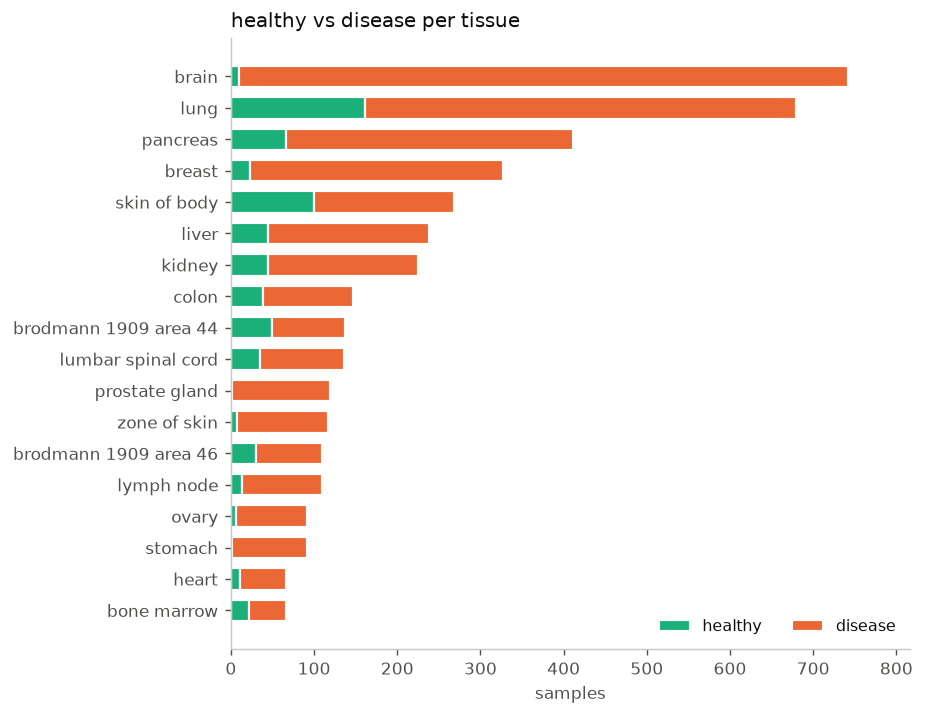

In [14]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))
left = np.zeros(len(piv))
for j, c_ in enumerate(keep):
    ax.barh(range(len(piv)), piv[c_].values, left=left, height=.68,
            color=[C[2], C[1]][j], label=c_, edgecolor="white", linewidth=1.2)
    left = left + piv[c_].values
ax.set_yticks(range(len(piv)))
ax.set_yticklabels([t.replace("_", " ")[:28] for t in piv.index])
ax.set_xlabel("samples"); ax.legend(frameon=False, ncol=2, fontsize=8.6, loc="lower right")
ax.set_xlim(0, piv.sum(axis=1).max() * 1.1)
ax.set_title("healthy vs disease per tissue", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f06_tissue_disease.png", bbox_inches="tight"); plt.show()

## 7. Not every matrix holds counts

Some depositors uploaded already-transformed values. They sit in the same depth range as raw
counts, so `normalize_total` and any count-based test accept them silently.

In [15]:
intg = a.is_integer.fillna(False).astype(bool)
neg = a[a.median_counts.fillna(0) < 0]
print(f"non-integer matrices: {int((~intg).sum()):,} of {len(a):,}")
print(f"NEGATIVE values (impossible for counts): {len(neg)} across {neg.accession.nunique()} studies")
by = (a.assign(nonint=~intg).groupby("technology_resolved")
        .agg(n=("sample_id", "size"), nonint=("nonint", "sum")))
by = by[by.n >= 20]; by["pct"] = (by.nonint / by.n * 100).round(1)
display(by.sort_values("pct", ascending=False))

non-integer matrices: 584 of 7,719
NEGATIVE values (impossible for counts): 33 across 30 studies


,n,nonint,pct
technology_resolved,,,
Slide-seq,199,167,83.9
Stereo-seq,106,11,10.4
Visium,5440,388,7.1
cell-level (unknown platform),27,1,3.7
CosMx,209,5,2.4
Xenium,1294,10,0.8
MERFISH,149,1,0.7
cell-level WTA,277,1,0.4


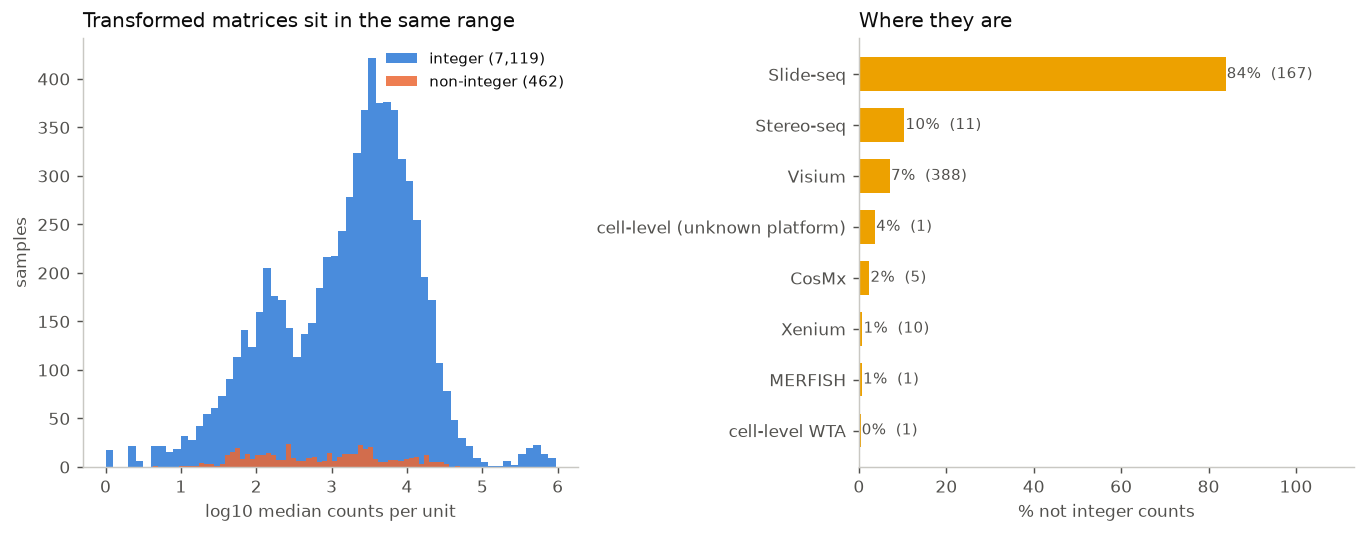

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2))
v = a[a.median_counts.notna() & a.median_counts.gt(0)]
vi = v.is_integer.fillna(False).astype(bool)
axes[0].hist(np.log10(v.loc[vi, "median_counts"]), bins=60, color=C[0], alpha=.85,
             label=f"integer ({int(vi.sum()):,})")
axes[0].hist(np.log10(v.loc[~vi, "median_counts"]), bins=60, color=C[1], alpha=.85,
             label=f"non-integer ({int((~vi).sum()):,})")
axes[0].set_xlabel("log10 median counts per unit"); axes[0].set_ylabel("samples")
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].set_title("Transformed matrices sit in the same range", color=INK)
b = by.sort_values("pct")
axes[1].barh(range(len(b)), b.pct, color=C[3], height=.66)
axes[1].set_yticks(range(len(b))); axes[1].set_yticklabels(b.index)
axes[1].set_xlabel("% not integer counts"); axes[1].set_xlim(0, max(b.pct.max() * 1.35, 1))
for i, (p_, n_) in enumerate(zip(b.pct, b.nonint)):
    axes[1].text(p_ + .25, i, f"{p_:.0f}%  ({n_})", va="center", fontsize=8.2, color=INK2)
axes[1].set_title("Where they are", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f07_integrity.png", bbox_inches="tight"); plt.show()

## 8. Panel size

A targeted platform only sees its panel, so two samples on different panels are not directly
comparable: a gene absent from a 300-plex panel was never measured.

In [17]:
TARGETED = ["Xenium", "CosMx", "MERFISH", "STARmap", "seqFISH"]
pan = a[a.n_genes.notna() & a.n_genes.gt(0)]
tg = pan[pan.technology_resolved.isin(TARGETED)]
print(f"{pan.n_genes.nunique()} distinct panel sizes | {tg.n_genes.nunique()} among targeted")
display(pan.groupby("technology_resolved").n_genes
        .agg(n="size", distinct="nunique", min="min", median="median", max="max")
        .query("n >= 10").astype(int))

588 distinct panel sizes | 117 among targeted


,n,distinct,min,median,max
technology_resolved,,,,,
CosMx,209,30,70,983,20386
MERFISH,149,11,180,315,1000
Slide-seq,199,113,5000,29196,60286
Stereo-seq,106,105,9095,42312,54056
Visium,5440,245,31,35477,116124
Xenium,1294,80,27,477,17061
cell-level (unknown platform),27,7,550,18085,38606
cell-level WTA,277,13,17943,18085,39125


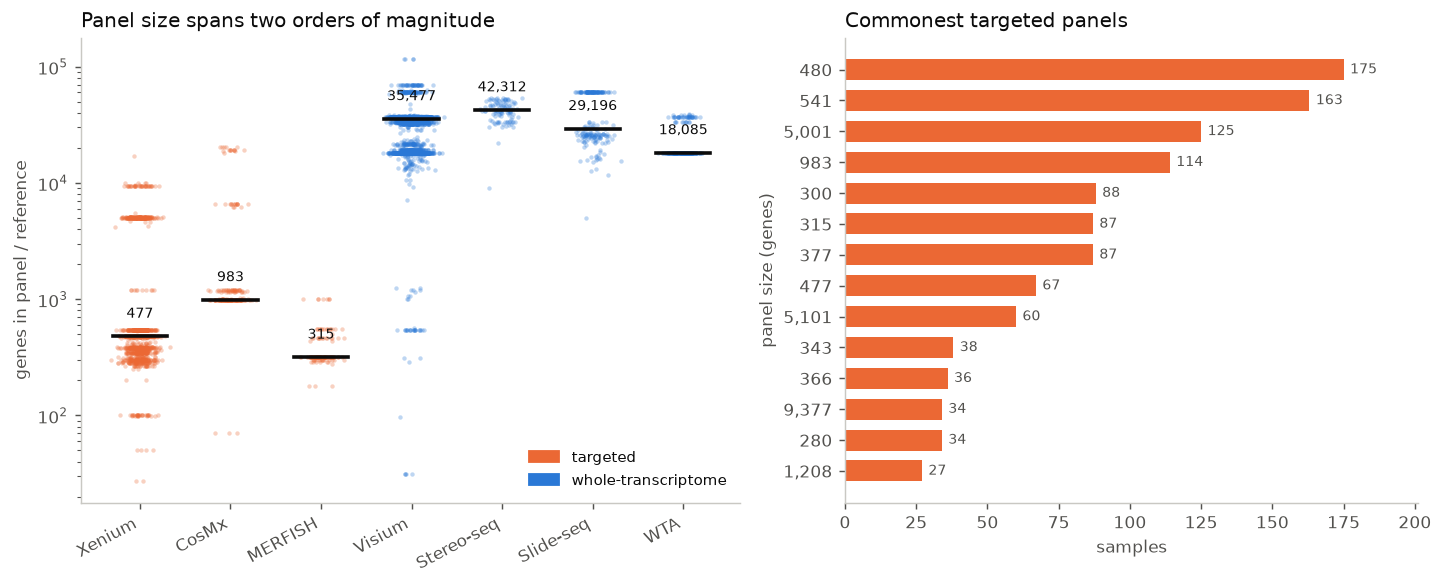

In [18]:
WTX = ["Visium", "Visium HD", "Stereo-seq", "Slide-seq", "cell-level WTA"]
labs = [t for t in TARGETED + WTX if (pan.technology_resolved == t).sum() >= 10]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
rng = np.random.default_rng(1)
for i, t in enumerate(labs):
    v = pan.loc[pan.technology_resolved.eq(t), "n_genes"].values
    axes[0].scatter(rng.normal(i, .09, len(v)), v, s=6,
                    color=C[1] if t in TARGETED else C[0], alpha=.3, lw=0)
    axes[0].plot([i - .3, i + .3], [np.median(v)] * 2, color=INK, lw=2, zorder=5)
    axes[0].text(i, np.median(v) * 1.45, f"{np.median(v):,.0f}", ha="center", fontsize=8, zorder=6)
axes[0].set_xticks(range(len(labs)))
axes[0].set_xticklabels([l.replace("cell-level ", "") for l in labs], rotation=28, ha="right")
axes[0].set_yscale("log"); axes[0].set_ylabel("genes in panel / reference")
axes[0].legend(handles=[mpl.patches.Patch(color=C[1], label="targeted"),
                        mpl.patches.Patch(color=C[0], label="whole-transcriptome")],
               frameon=False, loc="lower right", fontsize=8.5)
axes[0].set_title("Panel size spans two orders of magnitude", color=INK)
sizes = tg.n_genes.round().astype(int).value_counts().head(14).sort_values()
axes[1].barh(range(len(sizes)), sizes.values, color=C[1], height=.68)
axes[1].set_yticks(range(len(sizes))); axes[1].set_yticklabels([f"{s:,}" for s in sizes.index])
axes[1].set_xlabel("samples"); axes[1].set_ylabel("panel size (genes)")
axes[1].set_xlim(0, sizes.max() * 1.15)
for i, v in enumerate(sizes.values):
    axes[1].text(v + sizes.max() * .013, i, f"{v}", va="center", fontsize=8, color=INK2)
axes[1].set_title("Commonest targeted panels", color=INK)
fig.tight_layout(); fig.savefig(FIG / "f08_panels.png", bbox_inches="tight"); plt.show()

## Summary

**Can** - large and broad: thousands of samples over a thousand studies, hundreds of millions
of measured units, hundreds of tissues.

**Cannot, yet** - the binding constraint is not size. It is that donor metadata needed to
stratify is absent for most samples, that healthy controls are missing in the tissues with the
most disease samples, and that the largest set of samples sharing one gene space is a small
fraction of the whole. A scaling curve run over this atlas measures how much more of its
dominant tissues and platforms helps, which is not the same claim as how much atlas size helps.